    x   y
0   4  53
1   5  63
2  10  59
3   9  77
4  13  49
(75, 2)


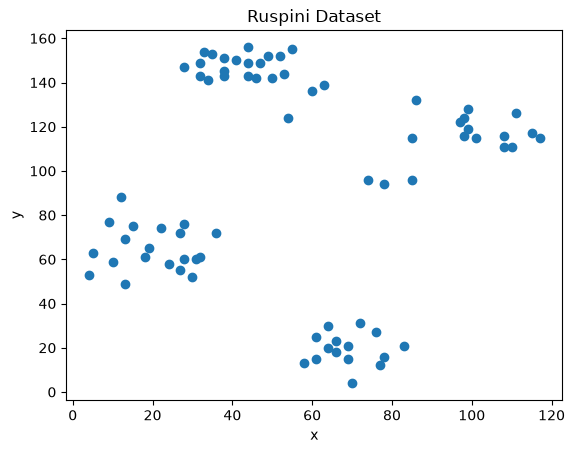

In [2]:
# get the Ruspini dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/cluster/ruspini.csv"
df = pd.read_csv(url)
df = df[["x", "y"]] # delete the 'rowname'

X = df.to_numpy()

print(df.head())
print(X.shape)

plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Ruspini Dataset")
plt.show()

In [3]:
# assign all points to the closet centroid
def assign_clusters(X, centroids):
    labels = []

    for point in X:
        distances = []

        for centroid in centroids:
            distance = np.sqrt((point[0] - centroid[0])**2 + (point[1] - centroid[1])**2)
            distances.append(distance)

        closest_cluster = np.argmin(distances) # get the index of minimal value
        labels.append(closest_cluster)

    return np.array(labels)

# recompute the centroid of each cluster
def update_centroids(X, labels, K):
    new_centroids = []

    for k in range(K):
        cluster_points = X[labels == k]
        new_centroid = cluster_points.mean(axis=0)
        new_centroids.append(new_centroid)

    return np.array(new_centroids)

# visualize iterations
def plot_iteration(X, labels, centroids, iteration):
    plt.figure(figsize=(7, 6))

    for k in range(len(centroids)):
        cluster_points = X[labels == k]
        plt.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            label=f"Cluster {k+1}"
        )

    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker="x",
        color="black",
        s=100,
        linewidths=2,
        label="Centroids"
    )

    plt.title(f"K-means Iteration {iteration}")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()

    plt.show()

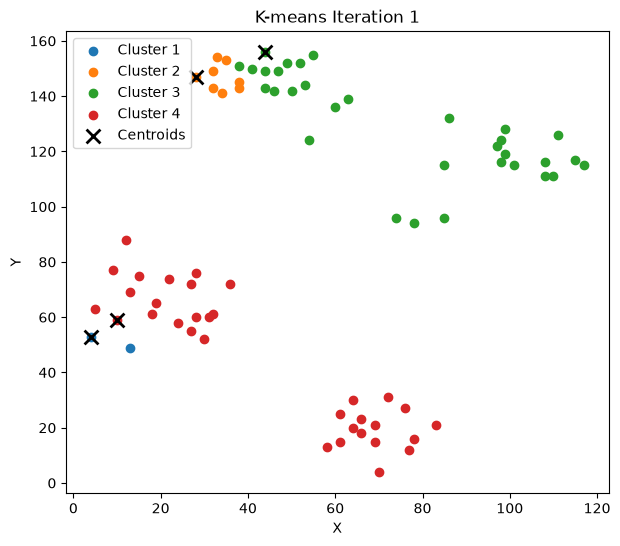

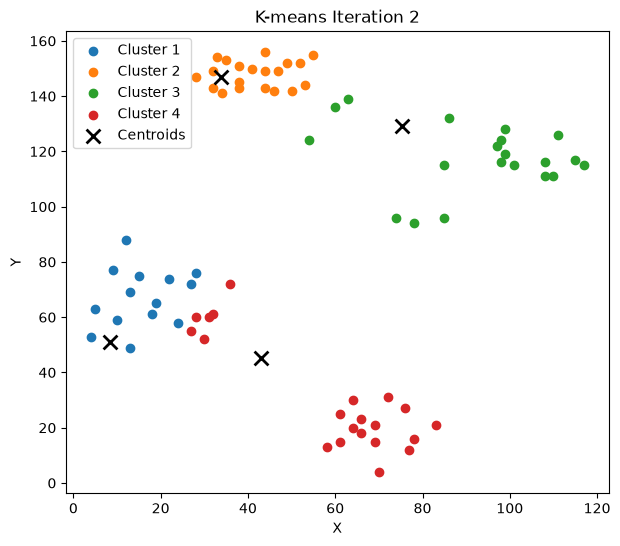

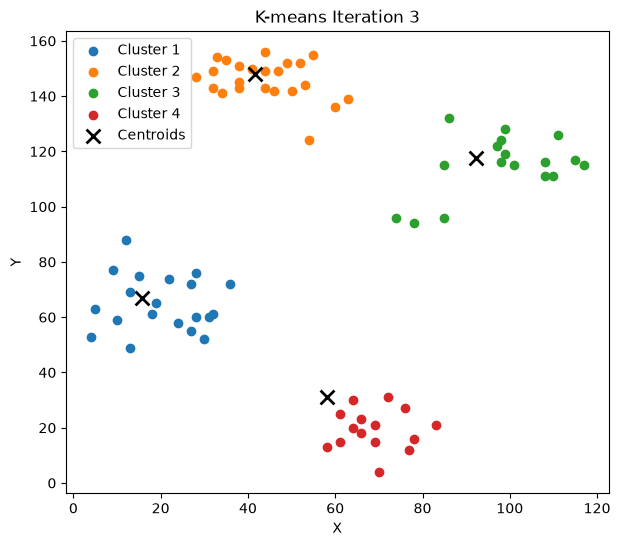

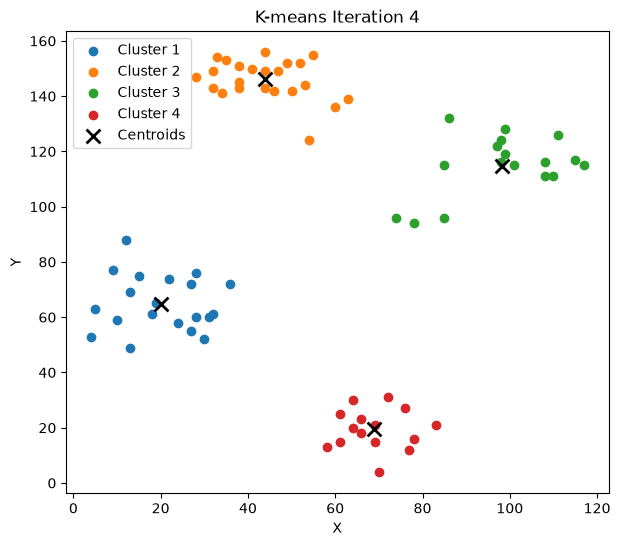

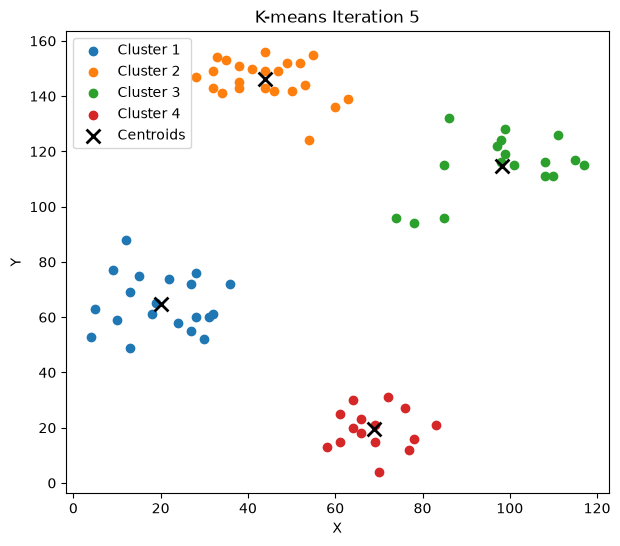

In [14]:
# successful run

K = 4
centroids = X[[0, 20, 30, 2]].astype(float)

for iteration in range(1, 6):

    labels = assign_clusters(X, centroids)

    plot_iteration(X, labels, centroids, iteration)

    centroids = update_centroids( X, labels, K)

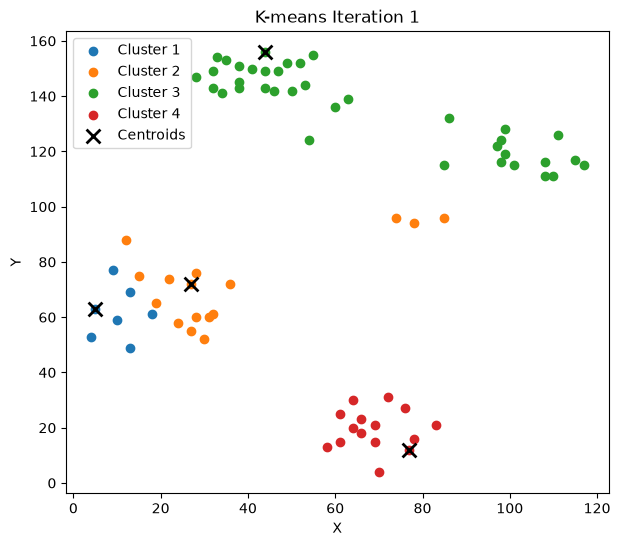

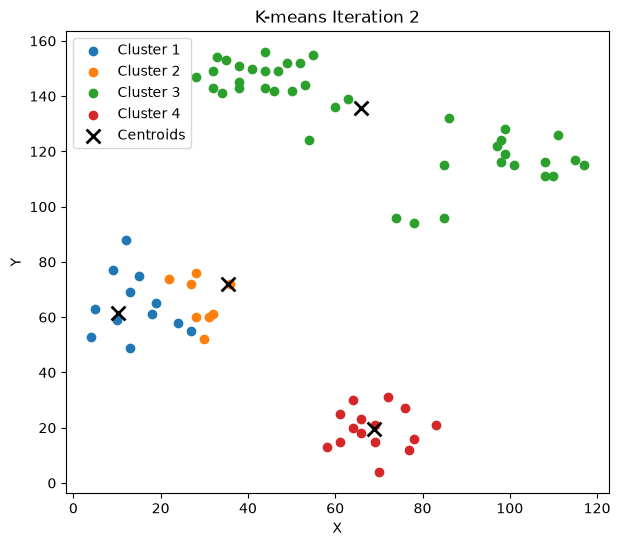

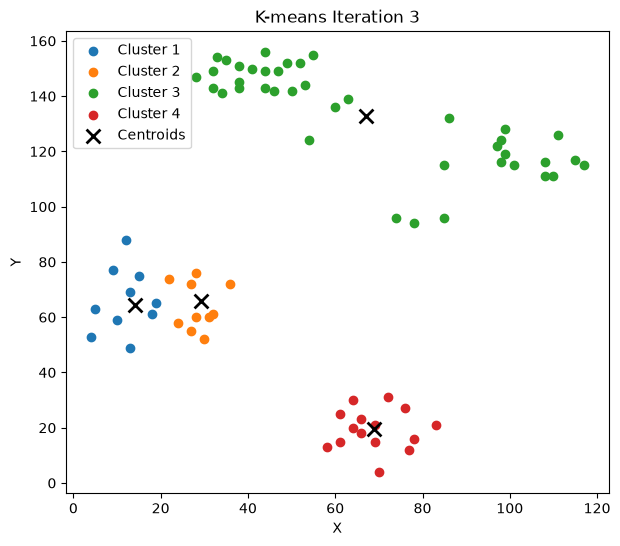

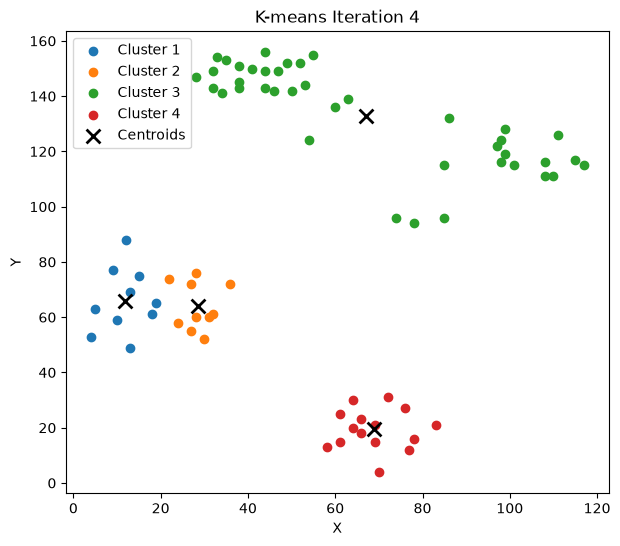

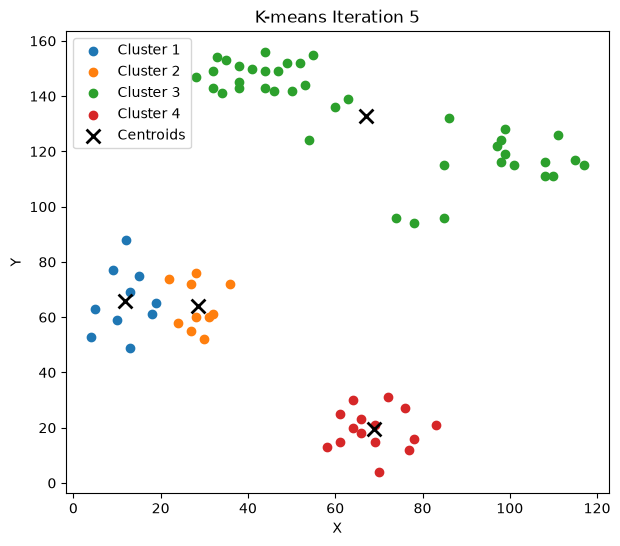

In [22]:
# unsuccessful run

K = 4
centroids = X[[1, 11, 30, 61]].astype(float)

for iteration in range(1, 6):

    labels = assign_clusters(X, centroids)

    plot_iteration(X, labels, centroids, iteration)

    centroids = update_centroids( X, labels, K)